# Soil Core Image Classification with CNN

Train a CNN on `grano1/core_sample_image_data` using its `HB` soil-core label. The dataset has official train/val/test splits. This model classifies the dataset label; it does not estimate nutrients or crops.

In [3]:
from pathlib import Path
import subprocess
import sys
cwd = Path.cwd().resolve()
candidates = [cwd / 'requirements-image.txt', cwd / 'ml_backend' / 'requirements-image.txt', cwd.parent / 'requirements-image.txt', cwd.parent.parent / 'ml_backend' / 'requirements-image.txt']
requirements = next((path for path in candidates if path.is_file()), None)
if requirements is None:
    raise FileNotFoundError(f'Could not find requirements-image.txt. Checked: {candidates}')
print('Installing from:', requirements)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(requirements)])

Installing from: D:\Work space\infosys springboard project\Infosys-Sp7.0-TeamB-Batch-4-Soil-Analytics\ml_backend\requirements-image.txt


0

In [4]:
from pathlib import Path
import copy
import json
import random
import numpy as np
import torch
from datasets import load_dataset
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
cwd = Path.cwd()
ROOT = cwd / 'ml_backend' if (cwd / 'ml_backend').is_dir() else (cwd.parent.parent if cwd.name == 'notebook' else cwd)
MODEL_DIR = ROOT / 'models' / 'image'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('Model directory:', MODEL_DIR.resolve())

c:\Users\ARJUN MITRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Model directory: D:\Work space\infosys springboard project\Infosys-Sp7.0-TeamB-Batch-4-Soil-Analytics\models\image


In [5]:
dataset = load_dataset('grano1/core_sample_image_data')
print(dataset)
print('Columns:', dataset['train'].column_names)
print('HB labels:', sorted(set(dataset['train']['HB'])))

DatasetDict({
    train: Dataset({
        features: ['Bildname', 'HB', 'NB', 'image'],
        num_rows: 2883
    })
    val: Dataset({
        features: ['Bildname', 'HB', 'NB', 'image'],
        num_rows: 360
    })
    test: Dataset({
        features: ['Bildname', 'HB', 'NB', 'image'],
        num_rows: 361
    })
})
Columns: ['Bildname', 'HB', 'NB', 'image']
HB labels: ['G', 'S', 'T', 'U', 'fG', 'fS', 'fS+U', 'fS+mS', 'gS', 'mG', 'mS']


## Exploratory data analysis

Inspect split sizes, label balance, metadata quality, image properties, and representative samples before training.

Split sizes:
  train: 2,883 images
  val: 360 images
  test: 361 images

Missing values by split:
  train: {'Bildname': 0, 'HB': 0, 'NB': 0, 'image': 0}
  val: {'Bildname': 0, 'HB': 0, 'NB': 0, 'image': 0}
  test: {'Bildname': 0, 'HB': 0, 'NB': 0, 'image': 0}

HB label distribution:
  train: {'G': 15, 'S': 16, 'T': 41, 'U': 295, 'fG': 13, 'fS': 1287, 'fS+U': 17, 'fS+mS': 32, 'gS': 233, 'mG': 11, 'mS': 923}
  val: {'G': 2, 'S': 2, 'T': 5, 'U': 37, 'fG': 1, 'fS': 161, 'fS+U': 2, 'fS+mS': 4, 'gS': 29, 'mG': 2, 'mS': 115}
  test: {'G': 2, 'S': 2, 'T': 5, 'U': 37, 'fG': 2, 'fS': 161, 'fS+U': 2, 'fS+mS': 4, 'gS': 29, 'mG': 1, 'mS': 116}

Sample image properties (up to 100 images per split):
  Sizes: {(330, 330): 300}
  Modes: {'RGB': 300}


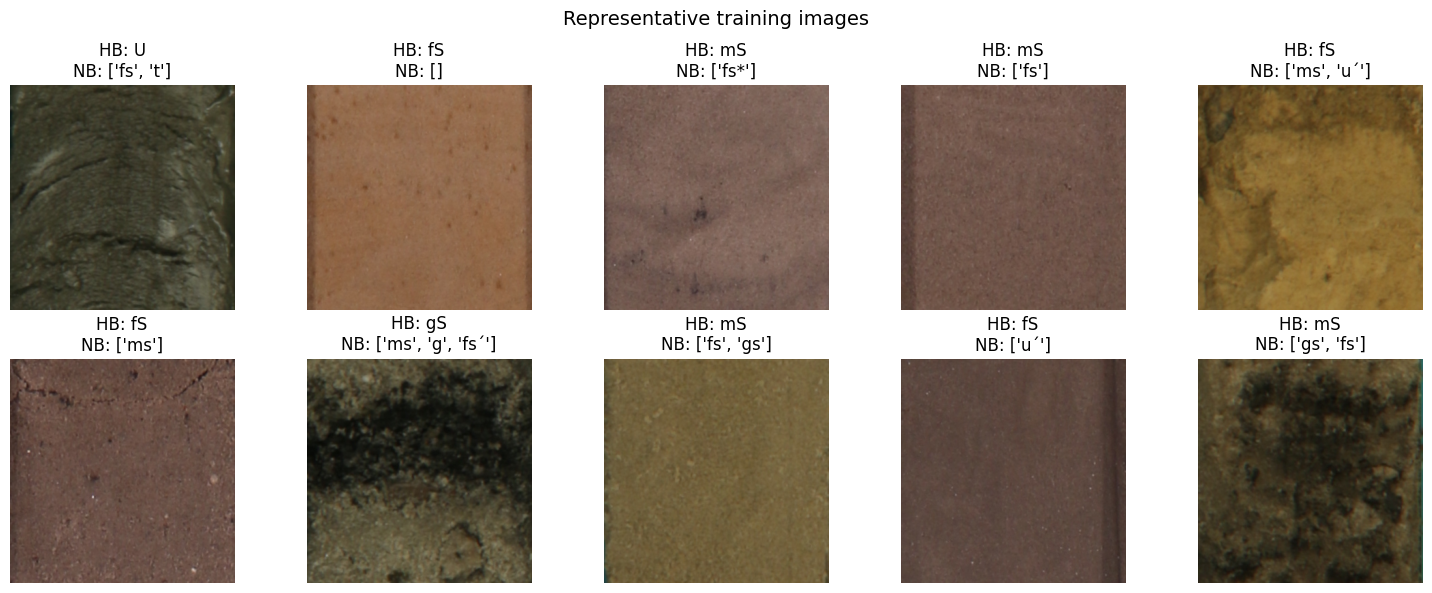

In [6]:
import matplotlib.pyplot as plt
from collections import Counter

print('Split sizes:')
for split_name, split in dataset.items():
    print(f'  {split_name}: {len(split):,} images')

print('\nMissing values by split:')
for split_name, split in dataset.items():
    missing = {column: sum(value is None for value in split[column]) for column in split.column_names}
    print(f'  {split_name}: {missing}')

print('\nHB label distribution:')
for split_name, split in dataset.items():
    counts = Counter(split['HB'])
    print(f'  {split_name}: {dict(sorted(counts.items()))}')

sample_rows = []
for split_name, split in dataset.items():
    for index in range(min(100, len(split))):
        image = split[index]['image']
        sample_rows.append((split_name, image.size, image.mode))
sizes = Counter(size for _, size, _ in sample_rows)
modes = Counter(mode for _, _, mode in sample_rows)
print('\nSample image properties (up to 100 images per split):')
print('  Sizes:', dict(sizes))
print('  Modes:', dict(modes))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for axis, index in zip(axes.flat, range(10)):
    row = dataset['train'][index]
    axis.imshow(row['image'])
    axis.set_title(f"HB: {row['HB']}\nNB: {row['NB']}")
    axis.axis('off')
fig.suptitle('Representative training images', fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
IMAGE_SIZE = 128
BATCH_SIZE = 32
NUM_WORKERS = 0
NORMALIZE = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.RandomHorizontalFlip(), transforms.RandomRotation(10), transforms.ColorJitter(brightness=0.15, contrast=0.15), transforms.ToTensor(), transforms.Normalize(*NORMALIZE)])
eval_transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor(), transforms.Normalize(*NORMALIZE)])

In [8]:
label_names = sorted(set(dataset['train']['HB']))
label_to_id = {label: index for index, label in enumerate(label_names)}

class SoilImageDataset(torch.utils.data.Dataset):
    def __init__(self, split, transform): self.split, self.transform = split, transform
    def __len__(self): return len(self.split)
    def __getitem__(self, index):
        row = self.split[index]
        return self.transform(row['image'].convert('RGB')), label_to_id[row['HB']]

train_data = SoilImageDataset(dataset['train'], train_transform)
val_data = SoilImageDataset(dataset['val'], eval_transform)
test_data = SoilImageDataset(dataset['test'], eval_transform)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print('Labels:', label_to_id)
print('Samples:', len(train_data), len(val_data), len(test_data))

Labels: {'G': 0, 'S': 1, 'T': 2, 'U': 3, 'fG': 4, 'fS': 5, 'fS+U': 6, 'fS+mS': 7, 'gS': 8, 'mG': 9, 'mS': 10}
Samples: 2883 360 361


In [9]:
class SoilCNN(nn.Module):
    def __init__(self, class_count):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.35), nn.Linear(256, class_count))
    def forward(self, images): return self.classifier(self.features(images))

model = SoilCNN(len(label_names)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
print(model)

SoilCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
 

In [10]:
def evaluate(loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(DEVICE))
            correct += (outputs.argmax(1).cpu() == labels).sum().item()
            total += labels.size(0)
    return correct / total

EPOCHS = 12
best_state = None; best_val_accuracy = 0.0; history = []
for epoch in range(EPOCHS):
    model.train(); running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(); loss = criterion(model(images), labels); loss.backward(); optimizer.step()
        running_loss += loss.item() * labels.size(0)
    val_accuracy = evaluate(val_loader); train_loss = running_loss / len(train_data)
    history.append({'epoch': epoch + 1, 'loss': train_loss, 'val_accuracy': val_accuracy})
    print(f'Epoch {epoch + 1:02d}/{EPOCHS} | loss={train_loss:.4f} | val_accuracy={val_accuracy:.4f}')
    if val_accuracy > best_val_accuracy: best_val_accuracy, best_state = val_accuracy, copy.deepcopy(model.state_dict())
if best_state is not None: model.load_state_dict(best_state)
test_accuracy = evaluate(test_loader)
print(f'Test accuracy: {test_accuracy:.4f}')

Epoch 01/12 | loss=1.1585 | val_accuracy=0.6667
Epoch 02/12 | loss=0.9862 | val_accuracy=0.6500
Epoch 03/12 | loss=0.9127 | val_accuracy=0.6528
Epoch 04/12 | loss=0.9026 | val_accuracy=0.6528
Epoch 05/12 | loss=0.8744 | val_accuracy=0.6972
Epoch 06/12 | loss=0.8263 | val_accuracy=0.6806
Epoch 07/12 | loss=0.8154 | val_accuracy=0.6306
Epoch 08/12 | loss=0.8473 | val_accuracy=0.7000
Epoch 09/12 | loss=0.8022 | val_accuracy=0.7167
Epoch 10/12 | loss=0.7779 | val_accuracy=0.7028
Epoch 11/12 | loss=0.7575 | val_accuracy=0.7194
Epoch 12/12 | loss=0.7704 | val_accuracy=0.7250
Test accuracy: 0.7230


In [11]:
if 'model' not in globals() or 'test_accuracy' not in globals():
    raise RuntimeError('Run all cells from the beginning, including the CNN training cell, before exporting the model.')
checkpoint = {'model_state_dict': model.cpu().state_dict(), 'class_names': label_names, 'image_size': IMAGE_SIZE, 'mean': NORMALIZE[0], 'std': NORMALIZE[1], 'test_accuracy': test_accuracy}
torch.save(checkpoint, MODEL_DIR / 'soil_core_cnn.pt')
(MODEL_DIR / 'class_names.json').write_text(json.dumps(label_names, indent=2), encoding='utf-8')
(MODEL_DIR / 'training_metrics.json').write_text(json.dumps({'history': history, 'test_accuracy': test_accuracy}, indent=2), encoding='utf-8')
print('Saved:', MODEL_DIR / 'soil_core_cnn.pt')

Saved: d:\Work space\infosys springboard project\Infosys-Sp7.0-TeamB-Batch-4-Soil-Analytics\models\image\soil_core_cnn.pt
